# 6 · Ortam sensörleri ve temizleme (Kriter 5 ve 6)

**Sorular:** Sensör değerleri nasıl dağılıyor? İmkânsız, takılı, eksik değerler var mı? Temizlik neyi değiştirdi
(öncesi–sonrası, sayıyla)? Normalizasyon neden ve nasıl?

**Kurallar `src/clean.py`'de**, her birinin gerekçesi `docs/VERI_SORUNLARI.md`'de. Diskteki veri ham hâlinde kalıyor;
temizlik okunurken uygulanıyor. Böylece öncesi–sonrası her zaman karşılaştırılabiliyor.

**Kurulum hücresi.** Önce bunu çalıştır (ya da Run → Run All). Kütüphaneleri, projenin `src/` kodlarını ve
etiketleri yükler; sonraki hücreler buradaki isimleri kullanır.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))           # projenin kendi kodları (src/) buradan çağrılır
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from build import OUT, INTERIM, ENV_COLS, HOMES, hubs_of
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLS = ["0 kişi", "1 kişi", "2+ kişi"]; RENK = ["#2A78D6", "#EB6834", "#1BAF7A"]   # bütün grafiklerde aynı renkler
LAB = {h: pd.read_parquet(OUT / h / "labels.parquet") for h in HOMES}           # etiketler (her ev için 10 sn ızgara)
print("evler:", HOMES, "| toplam pencere:", sum(map(len, LAB.values())))

evler: ['H1', 'H2', 'H3', 'H4', 'H5', 'H6'] | toplam pencere: 1311925


In [2]:
from clean import clean_env, fill_short_gaps, VALID, STUCK_RH_HUBS
AD = {"tvoc_ppb": "TVOC (ppb)", "temp_c": "Sıcaklık (°C)", "rh_percent": "Nem (%)", "light_lux": "Işık (lux)", "co2eq_ppm": "eCO2 (ppm)"}
RAW = {(h, hub): np.load(OUT / h / f"{hub}_env.npy") for h in HOMES for hub in hubs_of(h)}   # ham hizalı (küçük: hub başına 5 MB)
ALL = pd.DataFrame(np.concatenate(list(RAW.values())), columns=[AD[c] for c in ENV_COLS])
print("hub-pencere:", len(ALL)); ALL.describe().T.round(1)

hub-pencere: 6084425


,count,mean,std,min,25%,50%,75%,max
TVOC (ppb),5795480.0,21.9,111.4,0.0,0.0,0.0,0.0,12265.0
Sıcaklık (°C),5465099.0,28.2,3.1,-15.4,25.7,27.9,30.5,40.0
Nem (%),5465099.0,28.0,19.8,0.0,18.7,24.0,35.4,3305.6
Işık (lux),5795480.0,1666.9,5924.5,0.0,6.0,234.0,1410.0,319774.0
eCO2 (ppm),5795480.0,471.7,400.1,400.0,400.0,400.0,400.0,60000.0


**Hemen göze çarpan:** Nemin en büyük değeri yüzde 100'ü aşıyor, sıcaklığın en küçüğü eksi, ışık 100 binin üstünde.
Bunlar fiziksel olarak imkânsız (iç mekân); sensör okuma hatası.

## 6.1 Kural 1: aralık dışı değerler → boş (NaN)

In [3]:
print("geçerli aralıklar:", VALID)
for j, c in enumerate(ENV_COLS):
    lo, hi = VALID[c]; x = ALL.iloc[:, j]
    print(f"{AD[c]:14s} aralık dışı: {int(((x < lo) | (x > hi)).sum()):6,d}   (en küçük {x.min():,.1f}, en büyük {x.max():,.1f})")

geçerli aralıklar: {'temp_c': (0, 45), 'rh_percent': (0, 100), 'light_lux': (0, 100000.0), 'co2eq_ppm': (400, 60000), 'tvoc_ppb': (0, 60000)}
TVOC (ppb)     aralık dışı:      0   (en küçük 0.0, en büyük 12,265.0)
Sıcaklık (°C)  aralık dışı:      3   (en küçük -15.4, en büyük 40.0)
Nem (%)        aralık dışı:    128   (en küçük 0.0, en büyük 3,305.6)
Işık (lux)     aralık dışı:  1,049   (en küçük 0.0, en büyük 319,774.0)
eCO2 (ppm)     aralık dışı:      0   (en küçük 400.0, en büyük 60,000.0)


In [4]:
x = np.array([[0, 25.0, 3285.0, 10, 400], [5, -12.7, 40, 20, 450]], "float32")    # iki örnek satır
print("önce :", x.tolist()); print("sonra:", clean_env(x, "RS1", ENV_COLS).tolist())

önce : [[0.0, 25.0, 3285.0, 10.0, 400.0], [5.0, -12.699999809265137, 40.0, 20.0, 450.0]]
sonra: [[0.0, 25.0, nan, 10.0, 400.0], [5.0, nan, 40.0, 20.0, 450.0]]


Yalnız imkânsız okumalar siliniyor: nemde 128, ışıkta 1.049 okuma; toplamın binde birinden az. Dağılımın gövdesi değişmiyor.

## 6.2 Kural 2: takılı sensör (RS5 nemi)

nemin standart sapması en düşük hub'lar:
H2-RS5    0.36
H4-RS5    0.54
H5-RS5    0.62
H3-RS5    0.74
H6-BS2    2.44
H6-BS5    2.57
H6-BS3    2.64


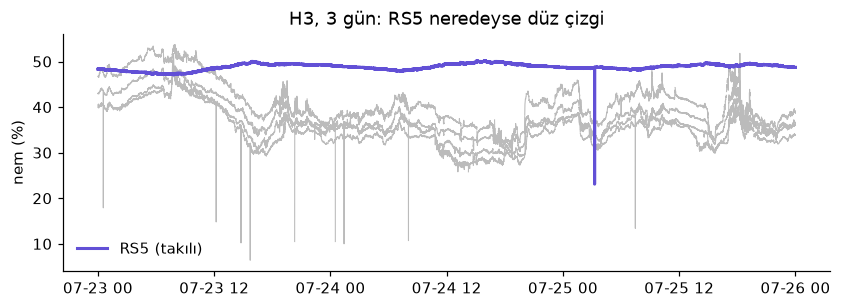

In [5]:
RH = ENV_COLS.index("rh_percent")
sd = pd.Series({f"{h}-{hub}": np.nanstd(clean_env(RAW[h, hub], "RS1", ENV_COLS)[:, RH]) for h, hub in RAW}).round(2)
print("nemin standart sapması en düşük hub'lar:"); print(sd.sort_values().head(7).to_string())
i0 = int(np.flatnonzero(LAB["H3"]["ts"] == "2019-07-23 00:00:00")[0]); sl = slice(i0, i0 + 3 * 8640)
plt.figure(figsize=(9, 2.8))
for hub in hubs_of("H3"):
    plt.plot(LAB["H3"]["ts"][sl], RAW["H3", hub][sl, RH], lw=2 if hub == "RS5" else 0.7,
             color="#6250D6" if hub == "RS5" else "#BBBBBB", label="RS5 (takılı)" if hub == "RS5" else None)
plt.ylabel("nem (%)"); plt.title("H3, 3 gün: RS5 neredeyse düz çizgi"); plt.legend(frameon=False); plt.show()

RS5 kutusu evden eve taşınmış aynı cihaz; nem sensörü hep %48–51 gösteriyor (std < 1, diğerlerinde 3–33). Bu kanal
tamamen çıkarılıyor (`STUCK_RH_HUBS`). Bilgi kaybı sınırlı: aynı evde 3–4 başka kutunun nemi var.

## 6.3 Kural 3: kısa boşlukları doldur, uzunları bırak

Sensör bazen birkaç satır atlıyor. En fazla 1 dakika (6 pencere) olan boşluklar iki yanındaki değerden **doğrusal** dolduruluyor
(ortam 1 dakikada pek değişmez). Daha uzun boşluğa değer uydurmak sahte veri üretmek olur → boş kalıp maskeleniyor.

In [6]:
g = np.array([[1], [np.nan], [np.nan], [4], [np.nan], [6]] + [[np.nan]] * 8 + [[9]], "float32")
print("önce :", g.ravel().tolist()); print("sonra:", np.round(fill_short_gaps(g).ravel(), 1).tolist(), " ← 8'lik boşluk dolmadı")
gap = []
for (h, hub), x in RAW.items():
    c = clean_env(x, hub, ENV_COLS)
    for j in range(5):
        if hub in STUCK_RH_HUBS and j == RH: continue          # bilerek silinen sensör boşluk sayılmaz
        m = np.isnan(c[:, j]); d = np.diff(np.r_[0, m.astype(int), 0])
        gap += list(np.flatnonzero(d == -1) - np.flatnonzero(d == 1))
gap = pd.Series(gap)
print(f"boşluk sayısı {len(gap):,}; ≤ 6 pencere olanlar %{100 * (gap <= 6).mean():.1f}; en uzun {gap.max():,} pencere (~{gap.max() * 10 / 86400:.0f} gün)")

önce : [1.0, nan, nan, 4.0, nan, 6.0, nan, nan, nan, nan, nan, nan, nan, nan, 9.0]
sonra: [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, nan, nan, nan, nan, nan, nan, nan, nan, 9.0]  ← 8'lik boşluk dolmadı


boşluk sayısı 653,466; ≤ 6 pencere olanlar %96.7; en uzun 99,150 pencere (~11 gün)


## 6.4 Öncesi–sonrası: tam satır oranı

In [7]:
rows = []
for (h, hub), x in RAW.items():
    c = clean_env(x, hub, ENV_COLS); f = fill_short_gaps(c)
    rows.append({"hub": f"{h}-{hub}", "RS5": hub == "RS5", "satır": len(x), "ham tam": (~np.isnan(x).any(1)).sum(),
                 "temizlik sonrası tam": (~np.isnan(c).any(1)).sum(), "doldurma sonrası tam": (~np.isnan(f).any(1)).sum()})
T = pd.DataFrame(rows); t = T[~T["RS5"]].drop(columns=["hub", "RS5"]).sum()
print("RS5 dışındaki hub'lar, bütün satırlar üzerinden:")
for k in ["ham tam", "temizlik sonrası tam", "doldurma sonrası tam"]: print(f"  {k:22s} %{100 * t[k] / t['satır']:.1f}")

RS5 dışındaki hub'lar, bütün satırlar üzerinden:
  ham tam                %89.5
  temizlik sonrası tam   %89.5
  doldurma sonrası tam   %96.1


Doldurma, RS5 dışındaki kutularda eksiksiz satır oranını ~%89,5'ten ~%96'ya çıkarıyor. RS5'te nem tümüyle boş olduğu için
"tam satır" orada hep düşük; bu beklenen durum.

## 6.5 Normalizasyon: kutu bazında z-skoru (sıcaklık örneği)

**Sorun:** Kutunun içindeki Raspberry Pi ısındığı için kutular farklı sıcaklık gösteriyor; Mart'taki H2 evi 33 °C görünüyor.
**Yöntem:** z = (değer − o kutunun ortalaması) / o kutunun standart sapması. Etiket kullanmaz; her kutu kendi verisinden.
**Sonuç:** 0 = "bu kutu için normal", +2 = "normalin çok üstü". Model "hangi kutu sıcak" yerine "sıcaklık değişti mi"ye bakar.

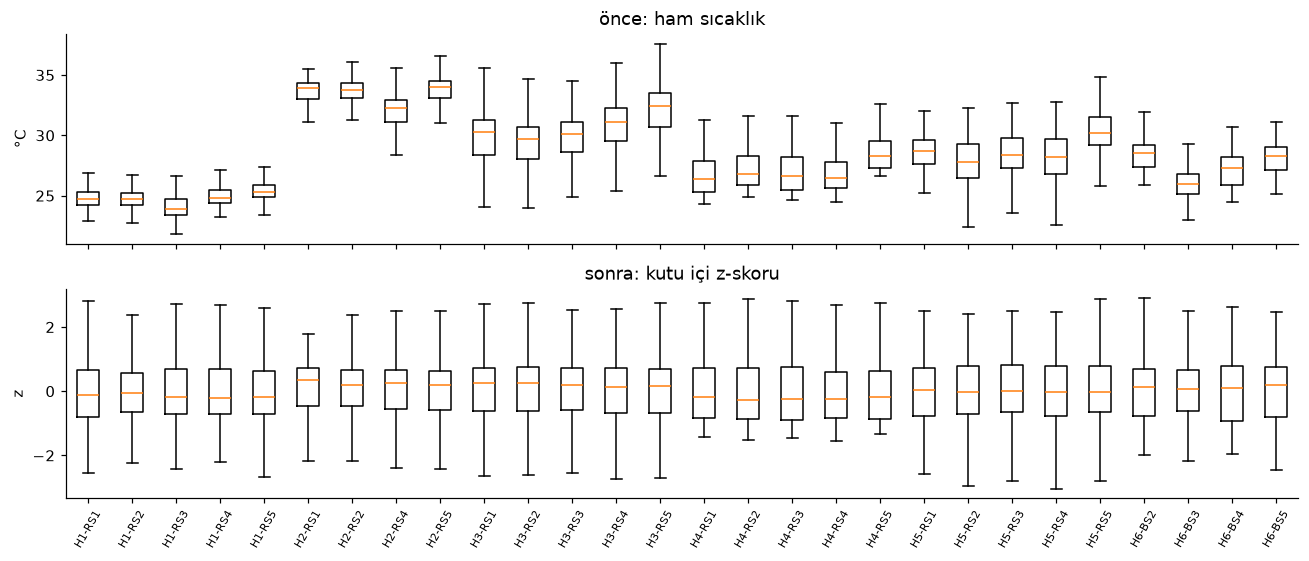

ham medyanlar 23.9 – 34.0 °C; en sıcak: H2-RS5


In [8]:
Tc = ENV_COLS.index("temp_c"); keys = list(RAW)
once = [clean_env(RAW[k], k[1], ENV_COLS)[::30, Tc] for k in keys]
sonra = [(v - np.nanmean(v)) / np.nanstd(v) for v in once]
fig, ax = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True)
ax[0].boxplot([v[~np.isnan(v)] for v in once], showfliers=False); ax[0].set_ylabel("°C"); ax[0].set_title("önce: ham sıcaklık")
ax[1].boxplot([v[~np.isnan(v)] for v in sonra], showfliers=False); ax[1].set_ylabel("z"); ax[1].set_title("sonra: kutu içi z-skoru")
ax[1].set_xticks(range(1, len(keys) + 1), [f"{h}-{b}" for h, b in keys], rotation=60, fontsize=7); plt.tight_layout(); plt.show()
med = pd.Series({f"{h}-{b}": np.nanmedian(v) for (h, b), v in zip(keys, once)})
print(f"ham medyanlar {med.min():.1f} – {med.max():.1f} °C; en sıcak: {med.idxmax()}")

## 6.6 Sınıflar arasında ortam farkı (temizlik + z sonrası)

,TVOC (ppb),Sıcaklık (°C),Nem (%),Işık (lux),eCO2 (ppm)
sınıf,,,,,
0 kişi,-0.13,-0.13,-0.10,-0.23,-0.06
1 kişi,-0.13,0.24,0.14,-0.35,-0.07
2+ kişi,-0.11,-0.06,-0.03,-0.50,-0.07


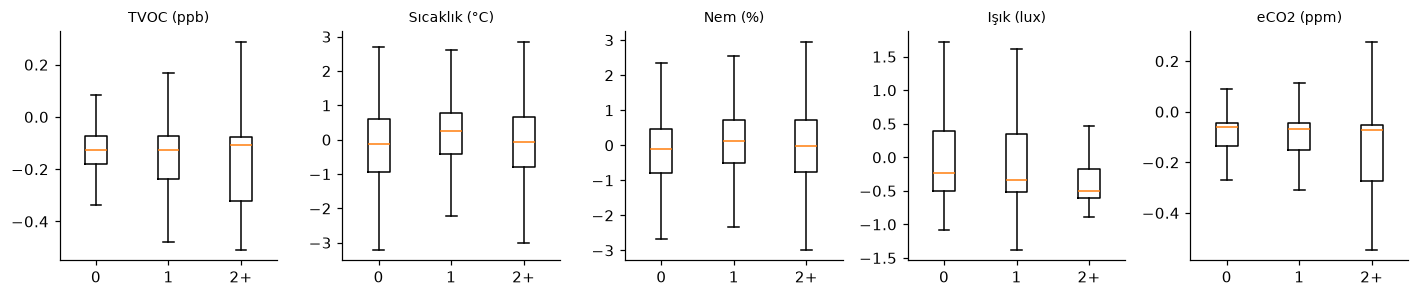

In [9]:
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)   # RS5 nemi tümüyle boş: beklenen uyarı
Z = []
for (h, hub), x in RAW.items():
    f = fill_short_gaps(clean_env(x, hub, ENV_COLS))
    z = (f - np.nanmean(f, 0)) / (np.nanstd(f, 0) + 1e-6)
    Z.append(pd.DataFrame(z[::20], columns=[AD[c] for c in ENV_COLS]).assign(sınıf=LAB[h]["cls"].to_numpy()[::20]))
Z = pd.concat(Z)
display(Z.groupby("sınıf").median().round(2).rename(index=dict(enumerate(CLS))))
fig, ax = plt.subplots(1, 5, figsize=(13, 2.8))
for a, c in zip(ax, Z.columns[:5]):
    a.boxplot([Z.loc[Z["sınıf"] == k, c].dropna() for k in range(3)], tick_labels=["0", "1", "2+"], showfliers=False); a.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

In [10]:
co2 = ALL["eCO2 (ppm)"]; tv = ALL["TVOC (ppb)"]
print(f"eCO2 = 400 (sensörün alt sınırı) olan oran: %{100 * (co2 == 400).mean():.0f};  TVOC = 0 olan oran: %{100 * (tv == 0).mean():.0f}")
display(Z.iloc[:, :5].corr(method="spearman").round(2))

eCO2 = 400 (sensörün alt sınırı) olan oran: %83;  TVOC = 0 olan oran: %83


,TVOC (ppb),Sıcaklık (°C),Nem (%),Işık (lux),eCO2 (ppm)
TVOC (ppb),1.00,0.17,0.07,0.05,0.76
Sıcaklık (°C),0.17,1.00,0.02,0.16,0.17
Nem (%),0.07,0.02,1.00,-0.00,0.06
Işık (lux),0.05,0.16,-0.00,1.00,0.04
eCO2 (ppm),0.76,0.17,0.06,0.04,1.00


**Gözlem:** Işık en ayırt edici sensör ama bilgisinin çoğu günün saatinden geliyor (gece 2+ ve karanlık). eCO2 ve TVOC
çoğunlukla sensörün taban değerinde; düşük konsantrasyonu ayırt edemiyor → bilgi taşıma kapasitesi düşük. **Final:** özellik
çıkarma (ablasyon) deneyiyle bu iki sensörün katkısına karar verilecek.